# Config

In [25]:
import os
import random
import numpy as np
import pandas as pd
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from torch import nn
from tqdm import tqdm
import torch

In [26]:
EPOCHS = 20
PATIENCE = 5
LR = 1e-4
SEED = 42

In [27]:
def set_seed(seed=42):
    # Python
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

    # NumPy
    np.random.seed(seed)

    # PyTorch CPU
    torch.manual_seed(seed)

    # PyTorch GPU
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # CUDNN
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# Prepare Dataset

## Load Dataset

In [28]:
transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Train:", len(train_dataset))
print("Test:", len(test_dataset))

Train: 60000
Test: 10000


## Plot Image

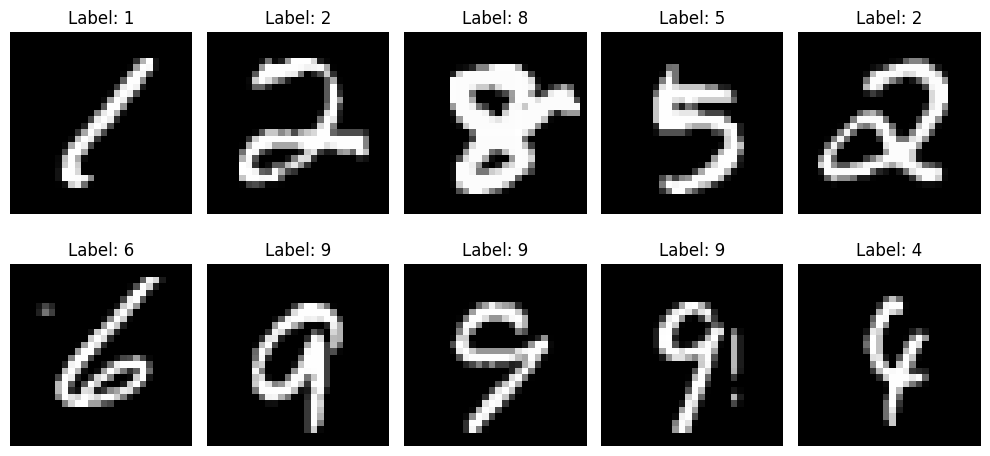

In [29]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Define Model

In [30]:
class FNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size = 3, stride = 2),
            nn.BatchNorm2d(8),
            nn.Flatten(),
            nn.Linear(13 * 13 * 8, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )
    def forward(self, x):
        return self.network(x)

# Training

In [31]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def calculate_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'Macro F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Weighted F1': f1_score(y_true, y_pred, average='weighted', zero_division=0)
    }

In [32]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model = FNN().to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=LR)
criterion = nn.CrossEntropyLoss()

for epoch in range(EPOCHS):

    # ========================== Train =========================== #
    model.train()

    train_loss = 0.0
    train_pred, train_gt = [], []

    for images, labels in tqdm(train_loader, desc='Training: '):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        preds = logits.argmax(dim=1)

        train_pred.extend(preds.cpu().numpy())
        train_gt.extend(labels.cpu().numpy())

        train_loss += loss.item()

    train_loss /= len(train_loader)

    train_metrics = calculate_metrics(train_gt, train_pred)

    # =========================== Valid =========================== #
    model.eval()

    val_loss = 0.0
    val_pred, val_gt = [], []

    with torch.inference_mode():
        for images, labels in tqdm(test_loader, desc='Validation: '):
            images, labels = images.to(device), labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            preds = logits.argmax(dim=1)

            val_pred.extend(preds.cpu().numpy())
            val_gt.extend(labels.cpu().numpy())

            val_loss += loss.item()

    val_loss /= len(test_loader)

    val_metrics = calculate_metrics(val_gt, val_pred)

    # =========================== Print =========================== #
    print(f'\nEpoch [{epoch + 1}/{EPOCHS}]')

    print(
        f'Train Loss: {train_loss:.4f} | '
        f'Accuracy: {train_metrics["Accuracy"]:.4f} | '
        f'Macro F1: {train_metrics["Macro F1"]:.4f}'
    )

    print(
        f'Val Loss: {val_loss:.4f} | '
        f'Accuracy: {val_metrics["Accuracy"]:.4f} | '
        f'Precision: {val_metrics["Precision"]:.4f} | '
        f'Recall: {val_metrics["Recall"]:.4f} | '
        f'Macro F1: {val_metrics["Macro F1"]:.4f} | '
        f'Weighted F1: {val_metrics["Weighted F1"]:.4f}'
    )

    print('-' * 100)

Validation: 100%|██████████| 157/157 [00:01<00:00, 151.66it/s]



Epoch [1/20]
Train Loss: 1.9476 | Accuracy: 0.3940 | Macro F1: 0.3682
Val Loss: 1.6229 | Accuracy: 0.6139 | Precision: 0.6107 | Recall: 0.6043 | Macro F1: 0.5830 | Weighted F1: 0.5900
----------------------------------------------------------------------------------------------------


Validation: 100%|██████████| 157/157 [00:01<00:00, 152.29it/s]



Epoch [2/20]
Train Loss: 1.4407 | Accuracy: 0.6782 | Macro F1: 0.6563
Val Loss: 1.2392 | Accuracy: 0.7485 | Precision: 0.7600 | Recall: 0.7411 | Macro F1: 0.7335 | Weighted F1: 0.7372
----------------------------------------------------------------------------------------------------


Validation: 100%|██████████| 157/157 [00:01<00:00, 139.62it/s]



Epoch [3/20]
Train Loss: 1.1532 | Accuracy: 0.7642 | Macro F1: 0.7529
Val Loss: 1.0115 | Accuracy: 0.8012 | Precision: 0.8092 | Recall: 0.7953 | Macro F1: 0.7919 | Weighted F1: 0.7946
----------------------------------------------------------------------------------------------------


... (30 outputs left out)

Validation: 100%|██████████| 157/157 [00:00<00:00, 162.46it/s]



Epoch [19/20]
Train Loss: 0.4399 | Accuracy: 0.8919 | Macro F1: 0.8905
Val Loss: 0.3941 | Accuracy: 0.9056 | Precision: 0.9048 | Recall: 0.9045 | Macro F1: 0.9043 | Weighted F1: 0.9052
----------------------------------------------------------------------------------------------------


Validation: 100%|██████████| 157/157 [00:00<00:00, 162.87it/s]


Epoch [20/20]
Train Loss: 0.4305 | Accuracy: 0.8949 | Macro F1: 0.8935
Val Loss: 0.3868 | Accuracy: 0.9069 | Precision: 0.9065 | Recall: 0.9058 | Macro F1: 0.9057 | Weighted F1: 0.9064
----------------------------------------------------------------------------------------------------
